# Asignación de canales Wi-Fi con QAOA: clásico vs cuántico-híbrido
**IBM Quantum Hackathon 2026 · Reto 5.2 — Algoritmos y aplicaciones**

Antenas Wi-Fi cercanas que transmiten en el mismo canal se interfieren. Este proyecto reparte **dos canales** entre las antenas para minimizar la interferencia, compara un algoritmo cuántico-híbrido (**QAOA**) con métodos clásicos y mide cómo cambia la ruta de los datos con cada asignación.

**Estructura del notebook**
1. El reto y la propuesta
2. Marco teórico
3. Parte 1 — Modelado de la red
4. Parte 2 — Solución cuántico-híbrida (QAOA)
5. Parte 3 — Soluciones clásicas y rutas
6. Parte 4 — Comparación
7. Escalamiento
8. Display completo
9. Alcance, conclusiones y referencias

In [1]:
import os, sys, warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)
sys.path.insert(0, os.getcwd())

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from canales import config
from canales.redes import pasillo, triangulos
from canales.escalamiento import barrido
from canales.formulacion import interferencia, interferencia_total_posible, hamiltoniano
from canales.cuantico import resolver_qaoa
from canales.clasico import resolver_fuerza_bruta, resolver_voraz, resolver_busqueda_local
from canales.rutas import mejor_ruta
from canales.metricas import tabla_comparativa, prob_optimo
from canales import visual as V

## 1. El reto y la propuesta
El reto pide un entorno que represente un problema de optimización, defina variables y costos, lo resuelva con enfoques clásicos y cuánticos o híbridos, y permita **visualizar y comparar** los resultados.

| Requisito del reto | Cómo lo cubre el proyecto |
|---|---|
| Conectar puntos / distribuir recursos | Repartir 2 canales entre antenas y enrutar datos entre ellas |
| Variables y costos | Un bit por antena (canal 0 o 1); costo = interferencia total y costo de la ruta |
| Restricciones | Cada antena usa exactamente un canal (implícito en la codificación binaria) |
| Clásico y cuántico/híbrido | Fuerza bruta, voraz y búsqueda local frente a QAOA |
| Visualizar y comparar | Mapas, tabla comparativa, histograma de QAOA, convergencia, escalamiento y display completo |

## 2. Marco teórico
**Antena = espín.** Cada antena $i$ toma un canal, representado por un espín $s_i=\pm1$. Si dos antenas a distancia corta comparten canal, pagan un costo $w_{ij}\ge 0$. La interferencia total es la energía de un **modelo de Ising antiferromagnético**:

$$E(s)=\sum_{(i,j)}\frac{w_{ij}}{2}\,(1+s_is_j).$$

**Equivalencia con MaxCut.** Sea $W=\sum w_{ij}$. Una arista contribuye $w_{ij}$ si sus extremos comparten canal y $0$ si no; por tanto, $E = W - \text{corte}$. Minimizar la interferencia es exactamente **MaxCut ponderado**, un problema que admite formulación de Ising [Lucas 2014, §2.2] y que el paquete oficial `qiskit-addon-opt-mapper` traduce a QUBO y a hamiltoniano [IBM, tutorial QAOA].

**Frustración.** Si tres antenas se interfieren entre sí (un ciclo impar), con dos canales al menos una pareja comparte canal: la interferencia mínima es mayor que cero, igual que en un antiferromagneto en red triangular.

**Más canales.** Con $k$ canales el problema se vuelve coloreo de grafos y requiere $N\cdot k$ espines con restricciones de penalización [Lucas 2014, §6.1]. Este proyecto se limita a $k=2$: un qubit por antena.

**Enfoque clásico.** El óptimo exacto se obtiene enumerando las $2^N$ asignaciones (viable para $N$ pequeño). Para MaxCut existe un algoritmo de aproximación clásico con garantía de al menos $0.878$ del óptimo [Goemans y Williamson 1995]. En la práctica de redes inalámbricas, la asignación de canales se modela con grafos de conflicto ponderados y heurísticas [Shin et al. 2024].

**Enfoque cuántico-híbrido.** QAOA prepara un circuito con $p$ capas cuyos ángulos ajusta un optimizador clásico; la calidad mejora al aumentar $p$, y para $p=1$ en grafos 3-regulares garantiza al menos $0.6924$ del corte óptimo [Farhi et al. 2014]. Si existe ventaja cuántica en optimización sigue siendo una pregunta abierta [Abbas et al. 2024]; por eso el objetivo aquí es **medir** y **comparar**, no suponer ventaja.

## 3. Parte 1 — Modelado de la red
La red se construye a partir de las posiciones de las antenas con una regla explícita (parámetros en `canales/config.py`):
- Dos antenas a menos de `RADIO_INTERFERENCIA` se interfieren con peso `PESO_MAXIMO · (1 − d / RADIO_INTERFERENCIA)`.
- Dos antenas a menos de `RADIO_COMUNICACION` tienen un enlace de datos con costo `COSTO_POR_METRO · d`.

La regla es una **simplificación propuesta por el equipo**: el peso decrece con la distancia, pero no proviene de un modelo de propagación. El caso de estudio son 6 antenas en un pasillo de dos filas separadas 3 m.

Parámetros de la red: {'RADIO_INTERFERENCIA': 4.5, 'PESO_MAXIMO': 5.0, 'RADIO_COMUNICACION': 4.5, 'COSTO_POR_METRO': 0.5}
Posiciones (m): [[0, 0], [3, 0], [6, 0], [0, 3], [3, 3], [6, 3]]
Antenas: 6 | parejas que se interfieren: 11 | enlaces de datos: 11
Interferencia si todas usan el mismo canal (W): 12.85


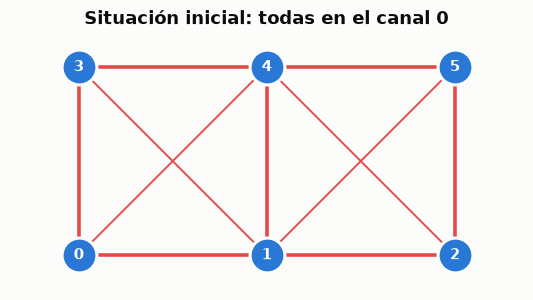

In [2]:
print("Parámetros de la red:", config.RED)
red = pasillo()
print("Posiciones (m):", red["pos"])

W = interferencia_total_posible(red)
print(f"Antenas: {red['n']} | parejas que se interfieren: {len(red['interf'])} | enlaces de datos: {len(red['com'])}")
print(f"Interferencia si todas usan el mismo canal (W): {W:.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
V.dibujar_red(red, [0] * red["n"], "Situación inicial: todas en el canal 0", ax, mostrar_ruta=False)
plt.show()

### Del modelo al lenguaje cuántico
La red se traduce red → MaxCut → QUBO → hamiltoniano. La celda verifica numéricamente la identidad *interferencia = W − corte* en todas las asignaciones posibles y muestra que basta **un qubit por antena**.

In [3]:
problema, H, offset = hamiltoniano(red)
asignaciones = list(itertools.product([0, 1], repeat=red["n"]))
error_max = max(abs(interferencia(red, x) - (W - problema.objective.evaluate(np.array(x)))) for x in asignaciones)
print(f"Qubits: {H.num_qubits} | términos ZZ: {len(H)} | error máximo de la identidad: {error_max:.1e}")
pd.DataFrame({"Término": [str(p) for p in H.paulis], "Coeficiente": H.coeffs.real.round(4)})

Qubits: 6 | términos ZZ: 11 | error máximo de la identidad: 3.6e-15


,Término,Coeficiente
0,IIIIZZ,0.835
1,IIZIIZ,0.835
2,IZIIIZ,0.145
3,IIIZZI,0.835
4,IIZIZI,0.145
5,IZIIZI,0.835
6,ZIIIZI,0.145
7,IZIZII,0.145
8,ZIIZII,0.835
9,IZZIII,0.835


**Transición a la Parte 2.** El hamiltoniano `H` codifica toda la interferencia: su estado de mínima energía es la mejor asignación de canales. QAOA busca ese estado.

## 4. Parte 2 — Solución cuántico-híbrida (QAOA)
Se sigue la receta del tutorial oficial de QAOA de IBM, ejecutada en simulador local:
1. `QAOAAnsatz` construye el circuito a partir de `H` con `REPS` capas (`2·REPS` ángulos).
2. `StatevectorEstimator` evalúa la energía para unos ángulos dados.
3. `scipy.optimize.minimize` (COBYLA) ajusta los ángulos: esta es la parte **híbrida**.
4. `StatevectorSampler` mide el circuito optimizado `SHOTS` veces.

Se reportan dos respuestas: la asignación **más probable** y la **mejor** entre todas las medidas.

Parámetros de QAOA: {'REPS': 2, 'SHOTS': 4000, 'OPTIMIZADOR': 'COBYLA', 'MAX_ITER': 300, 'SEMILLA': 7}


Profundidad: 5 | evaluaciones: 300 | tiempo: 30.7 s
Más probable: [1, 0, 1, 0, 1, 0] -> interferencia 1.16
Mejor muestra: [0, 1, 0, 1, 0, 1] -> interferencia 1.16


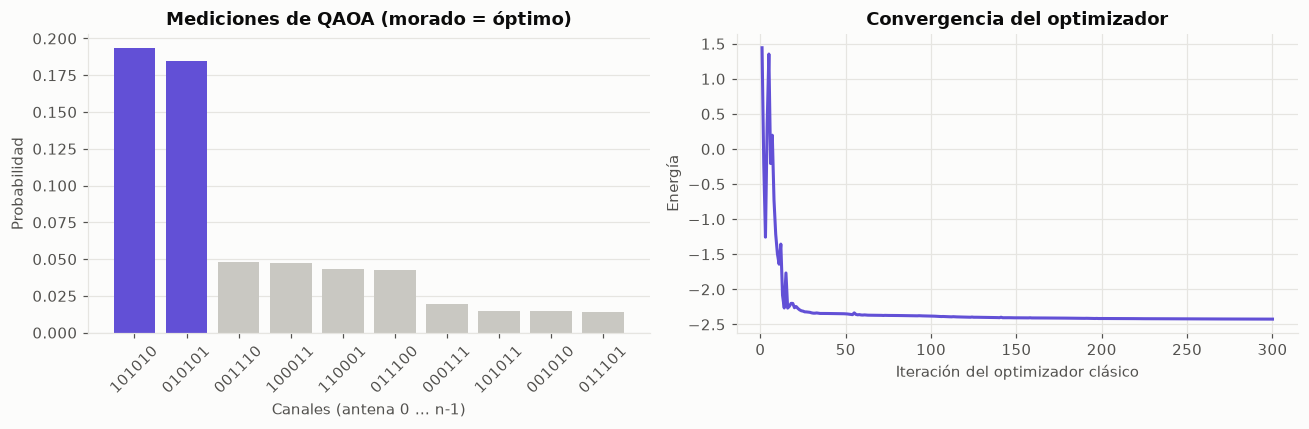

In [4]:
print("Parámetros de QAOA:", config.QAOA)
q = resolver_qaoa(red)
e = q["extra"]
print(f"Profundidad: {e['profundidad']} | evaluaciones: {e['evaluaciones']} | tiempo: {q['tiempo_s']:.1f} s")
print(f"Más probable: {e['x_mas_probable']} -> interferencia {e['costo_mas_probable']:.2f}")
print(f"Mejor muestra: {q['x']} -> interferencia {q['costo']:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
optimo_ref = min(interferencia(red, x) for x in asignaciones)
V.histograma_qaoa(red, q, optimo_ref, ax[0])
V.convergencia(q, ax[1])
plt.tight_layout(); plt.show()

**Transición a la Parte 3.** QAOA entrega asignaciones, pero sin una referencia no se sabe si son buenas. La Parte 3 calcula el óptimo exacto y dos heurísticas clásicas, y evalúa el efecto de cada asignación sobre las rutas.

## 5. Parte 3 — Soluciones clásicas y rutas
- **Fuerza bruta:** enumera las $2^N$ asignaciones; da el óptimo exacto (referencia).
- **Voraz:** las antenas más interferidas eligen primero el canal con menos conflicto.
- **Búsqueda local:** parte de asignaciones aleatorias y cambia una antena mientras mejore, con varios reinicios.

**Rutas.** El costo de un enlace es *costo base + α · interferencia en sus dos extremos*; la ruta más barata se obtiene con Dijkstra (`rustworkx`). La dependencia con α es un modelo propuesto, no una ley física; conecta la asignación de canales con la calidad de la comunicación.

Parámetros clásicos: {'MAX_ANTENAS_FUERZA_BRUTA': 20, 'REINICIOS': 20, 'SEMILLA': 0} | rutas: {'ALPHA': 0.5}
Fuerza bruta    canales=[0, 1, 0, 1, 0, 1] interferencia=1.16 tiempo=0.08 ms
Voraz           canales=[1, 0, 1, 0, 1, 0] interferencia=1.16 tiempo=0.09 ms
Busqueda local  canales=[1, 0, 1, 0, 1, 0] interferencia=1.16 tiempo=0.71 ms


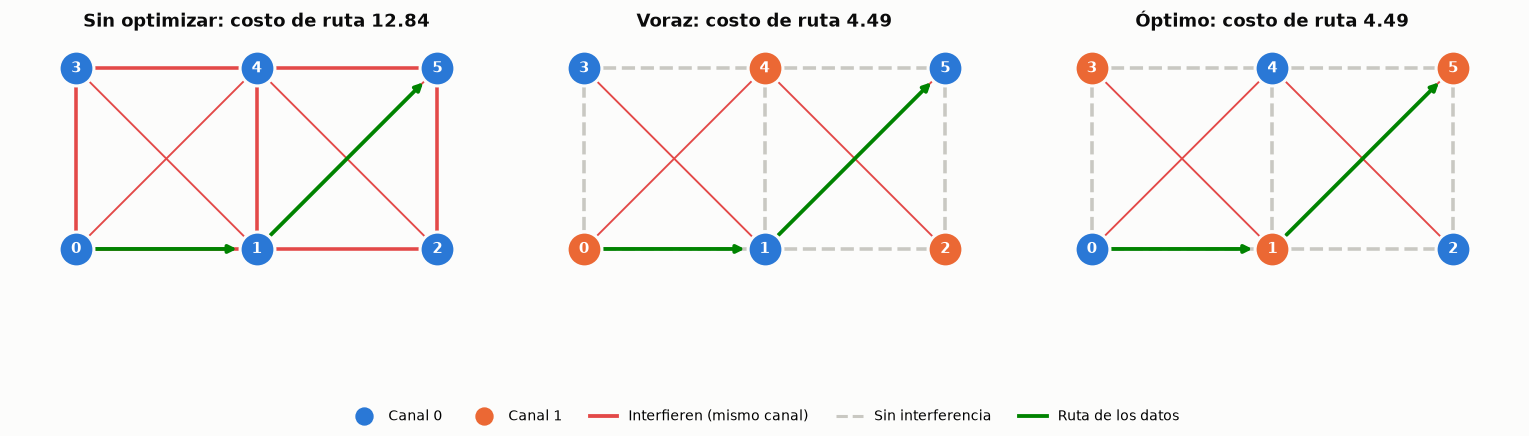

In [5]:
print("Parámetros clásicos:", config.CLASICO, "| rutas:", config.RUTAS)
clasicos = [resolver_fuerza_bruta(red), resolver_voraz(red), resolver_busqueda_local(red)]
for r in clasicos:
    print(f"{r['metodo']:15s} canales={r['x']} interferencia={r['costo']:.2f} tiempo={r['tiempo_s']*1e3:.2f} ms")

casos = {"Sin optimizar": [0] * red["n"], "Voraz": clasicos[1]["x"], "Óptimo": clasicos[0]["x"]}
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
for a, (nombre, x) in zip(ax, casos.items()):
    V.dibujar_red(red, x, f"{nombre}: costo de ruta {mejor_ruta(red, x)['costo']}", a)
V.leyenda_red(fig); plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

**Transición a la Parte 4.** Con la referencia exacta, las heurísticas y QAOA, se arma una tabla única con las mismas métricas para todos.

## 6. Parte 4 — Comparación
Métricas: interferencia, distancia al óptimo, ruta y su costo, tiempo; para QAOA además **P(óptimo)** (fracción de mediciones que dan una solución óptima) y la interferencia de su resultado más probable. Se usa la diferencia absoluta y no un cociente, porque el óptimo puede valer cero.

Se comparan dos redes: el caso de estudio y una red de 5 antenas con frustración más marcada.

,Metodo,Interferencia,Distancia al optimo,Ruta,Costo ruta,Tiempo (s),P(optimo),Interf. mas probable
0,Fuerza bruta,1.16,0.0,0-1-5,4.49,0.0001,NaN,NaN
1,Voraz,1.16,0.0,0-1-5,4.49,0.0001,NaN,NaN
2,Busqueda local,1.16,0.0,0-1-5,4.49,0.0007,NaN,NaN
3,QAOA,1.16,0.0,0-1-5,4.49,30.6711,0.378,1.16


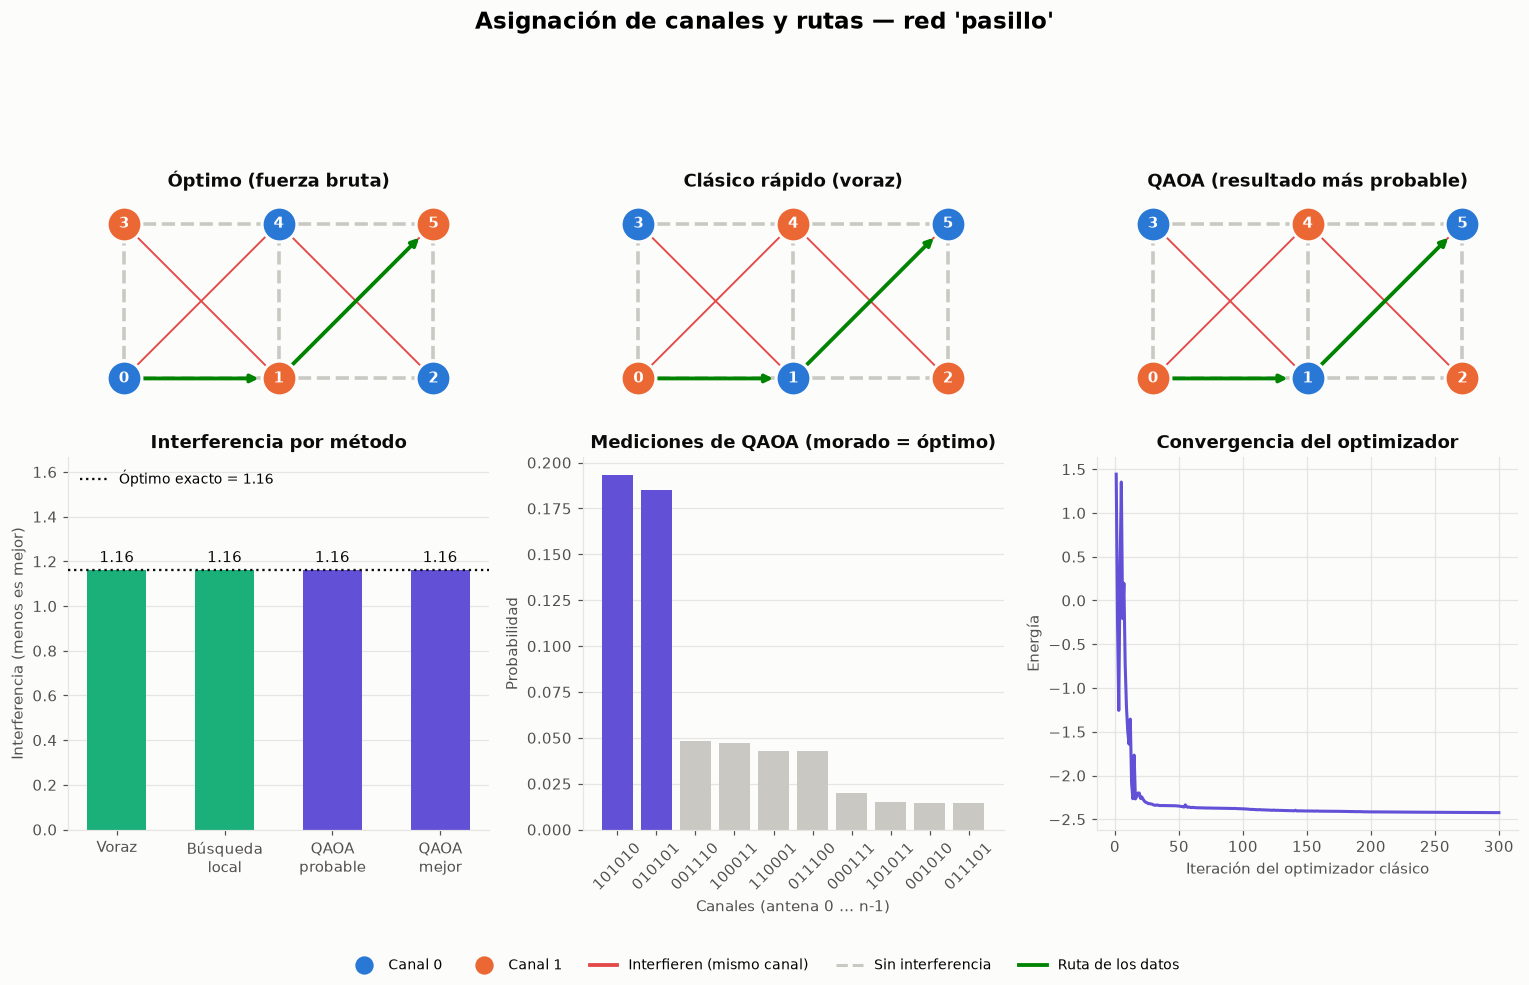

In [6]:
resultados = clasicos + [q]
filas = tabla_comparativa(red, resultados)
display(pd.DataFrame(filas))
V.armar_tablero(red, resultados, filas)
plt.show()

,Metodo,Interferencia,Distancia al optimo,Ruta,Costo ruta,Tiempo (s),P(optimo),Interf. mas probable
0,Fuerza bruta,1.0,0.0,0-1-3-4,4.0,0.0000,NaN,NaN
1,Voraz,1.0,0.0,0-1-3-4,4.0,0.0001,NaN,NaN
2,Busqueda local,1.0,0.0,0-1-3-4,4.0,0.0009,NaN,NaN
3,QAOA,1.0,0.0,0-1-3-4,4.0,3.6729,0.112,3.5


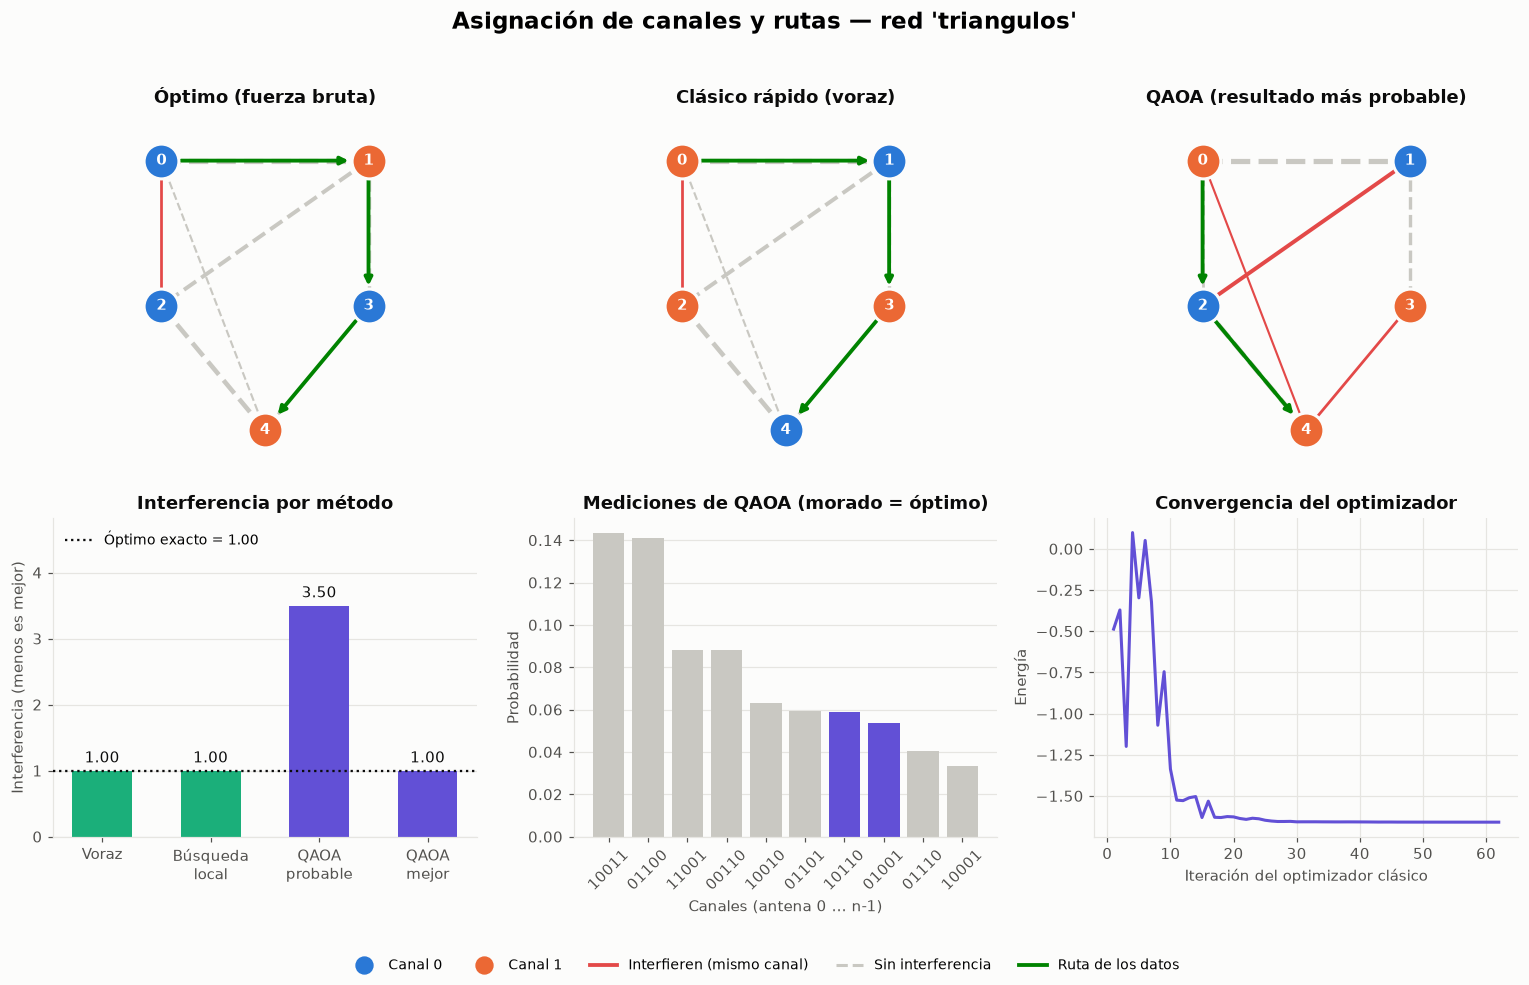

In [7]:
red_b = triangulos()
resultados_b = [resolver_fuerza_bruta(red_b), resolver_voraz(red_b), resolver_busqueda_local(red_b), resolver_qaoa(red_b)]
filas_b = tabla_comparativa(red_b, resultados_b)
display(pd.DataFrame(filas_b))
V.armar_tablero(red_b, resultados_b, filas_b)
plt.show()

## 7. Escalamiento
Se resuelven redes aleatorias de 4 a 7 antenas (2 semillas por tamaño) con QAOA de 1 y 2 capas y con fuerza bruta. La línea punteada de la izquierda es la probabilidad de acertar eligiendo al azar ($2/2^N$, por la simetría de intercambiar canales).

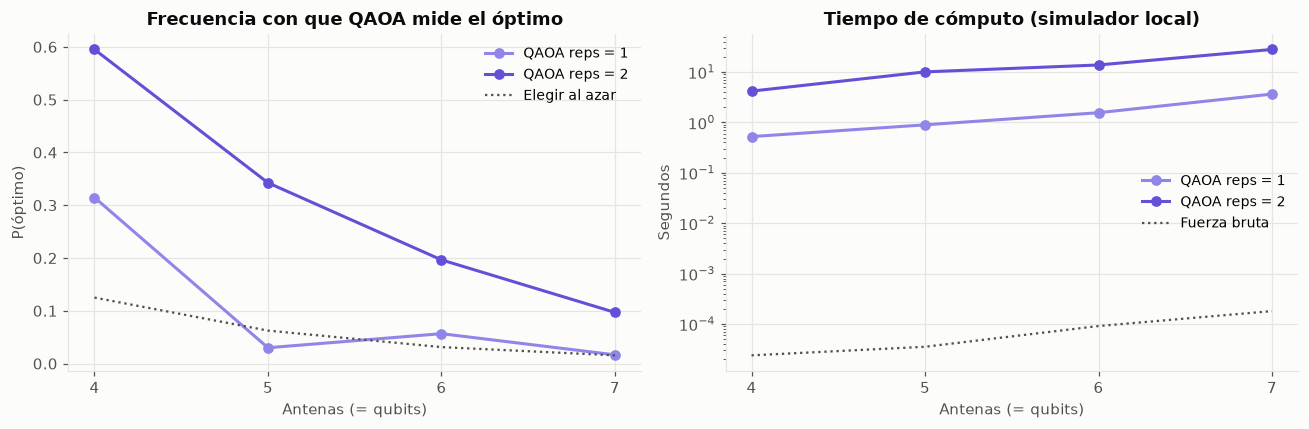

,n,semilla,reps,optimo,p_optimo,acierta_mas_probable,tiempo_qaoa_s,tiempo_fuerza_bruta_s,profundidad
0,4,0,1,0.00,0.6170,True,0.429,0.000020,3
1,4,0,2,0.00,0.6952,True,7.277,0.000020,5
2,4,1,1,0.00,0.0123,False,0.618,0.000028,3
3,4,1,2,0.00,0.4950,True,1.079,0.000028,5
4,5,0,1,2.54,0.0320,False,0.830,0.000040,3
5,5,0,2,2.54,0.2555,True,5.057,0.000040,5
6,5,1,1,0.41,0.0280,False,0.961,0.000031,3
7,5,1,2,0.41,0.4295,False,15.064,0.000031,5
8,6,0,1,2.54,0.0517,False,1.296,0.000126,3
9,6,0,2,2.54,0.2115,True,12.147,0.000126,5


In [8]:
esc = barrido()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
V.escalamiento(esc, ax[0], ax[1])
plt.tight_layout(); plt.show()
pd.DataFrame(esc)

## 8. Display completo
El display reúne en una sola vista el recorrido del proyecto: la red inicial, el óptimo exacto, el resultado de QAOA, la heurística voraz, las mediciones de QAOA, la convergencia del optimizador, la comparación de interferencias, el costo de la ruta según cada asignación y un resumen numérico que incluye la probabilidad de acertar al azar ($2/2^N$) como referencia. Es la misma vista que genera `demo.py`.

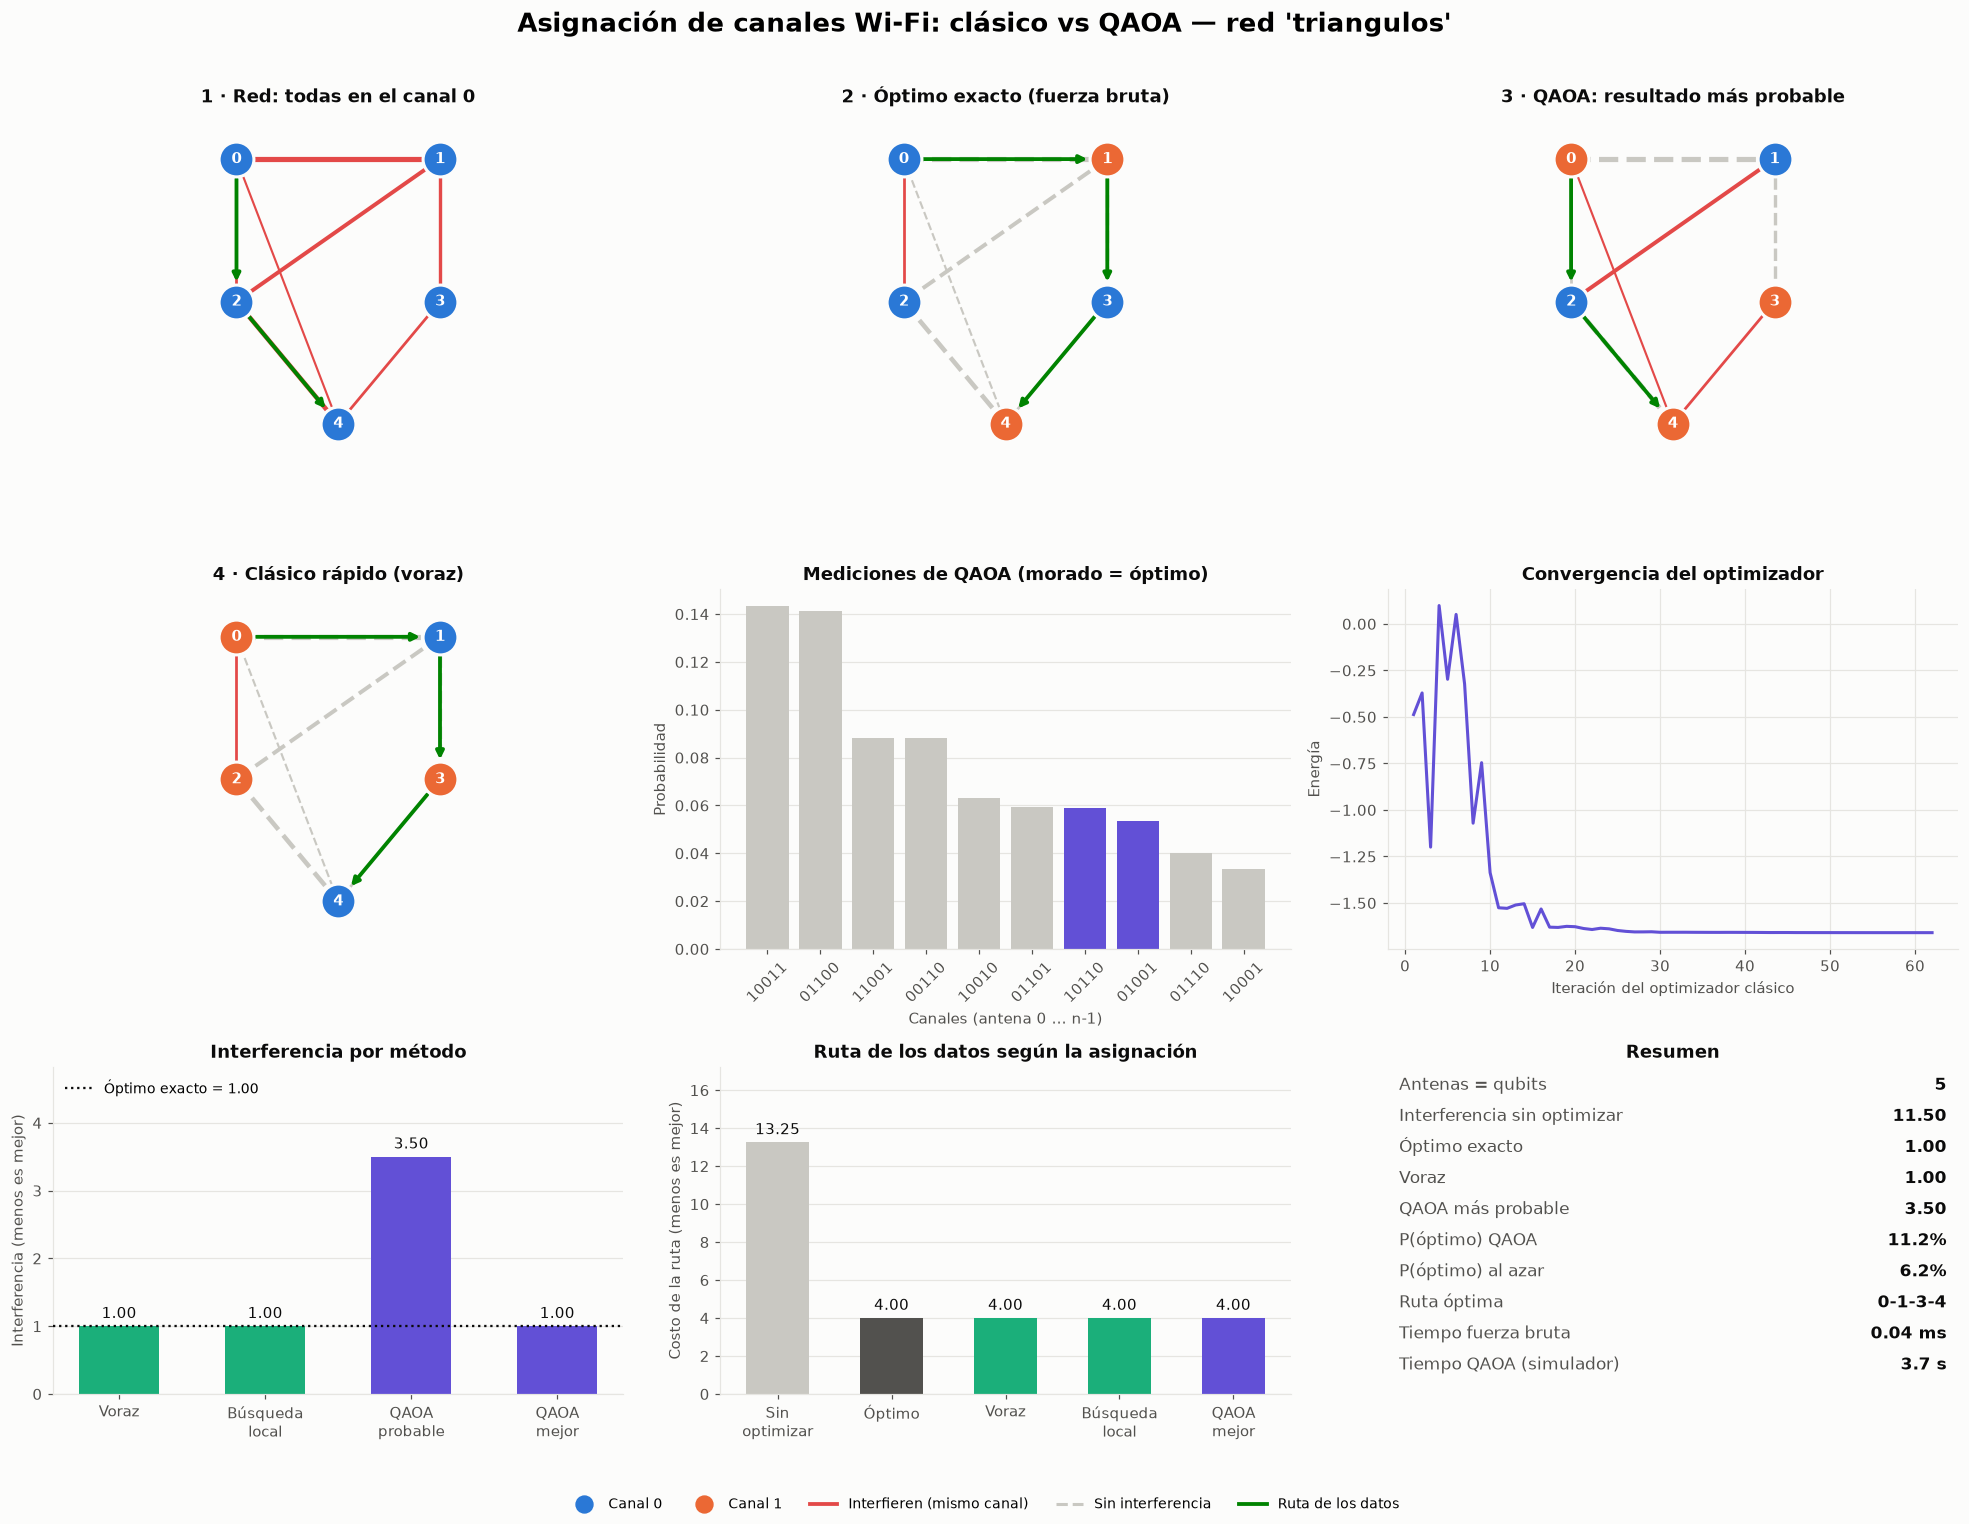

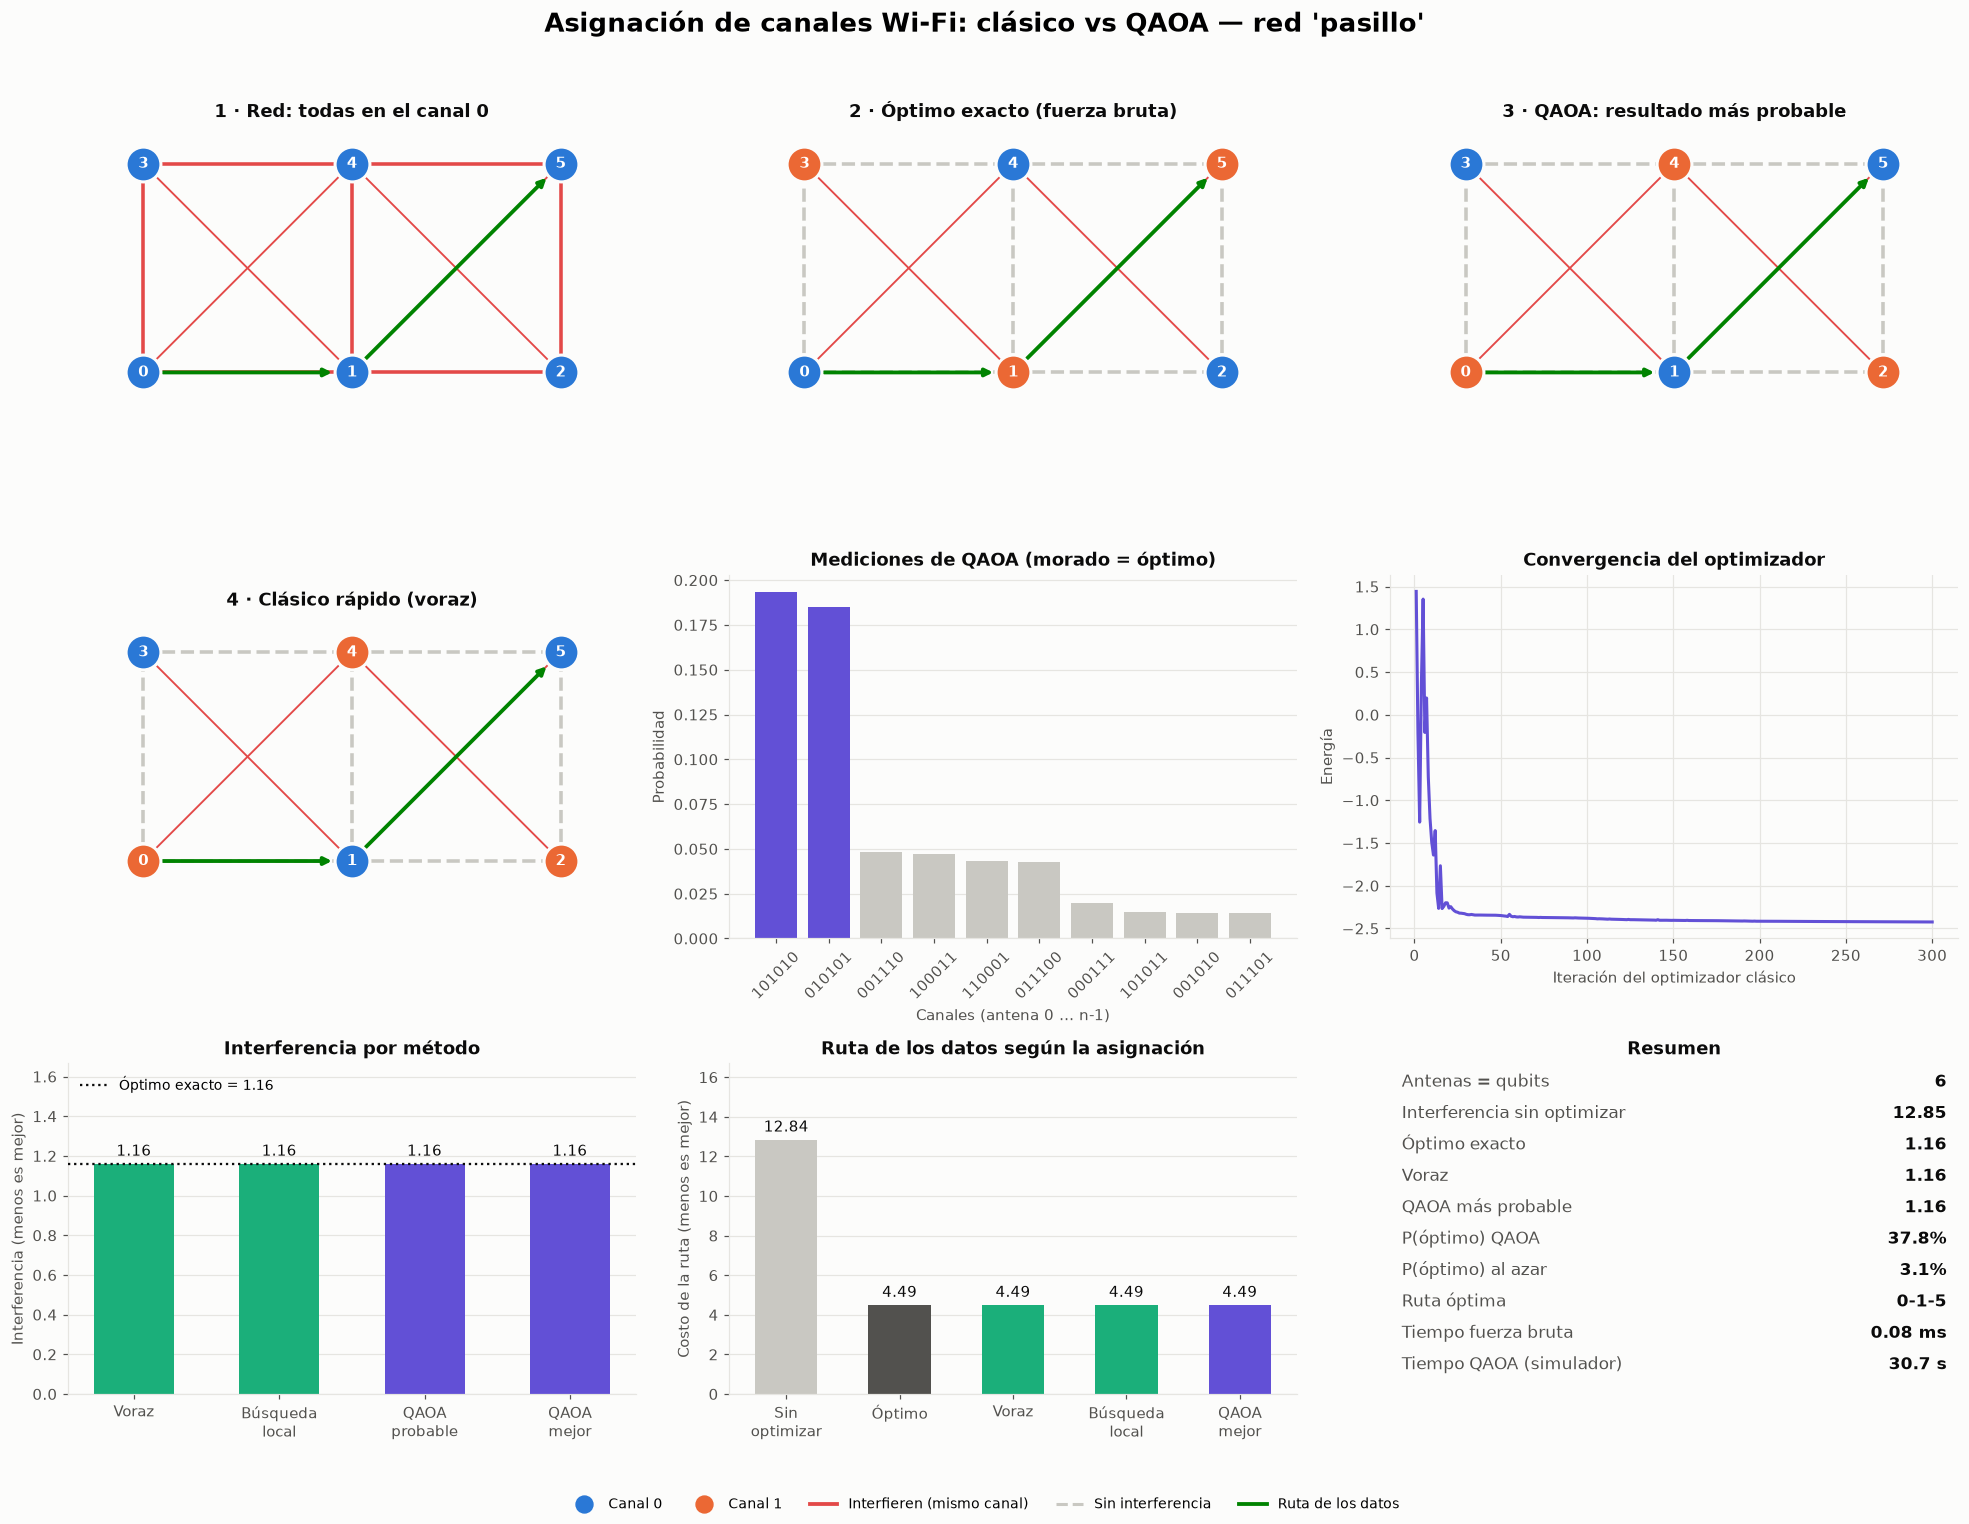

In [9]:
V.armar_display(red_b, resultados_b, filas_b)
plt.show()
V.armar_display(red, resultados, filas)
plt.show()

## 9. Alcance y conclusiones
| Fortalezas | Limitaciones |
|---|---|
| El problema es directamente un hamiltoniano de Ising: un qubit por antena | A este tamaño, los métodos clásicos son órdenes de magnitud más rápidos |
| QAOA concentra la probabilidad en buenas soluciones: mide el óptimo con más frecuencia que el azar | Su resultado más probable no siempre es el óptimo |
| La calidad mejora con más capas [Farhi et al. 2014] | Más capas implican circuitos más profundos y más ruido en hardware real |
| La misma formulación puede ejecutarse en hardware de IBM | Garantía conocida de QAOA ($p=1$, 3-regulares: 0.6924) inferior a Goemans–Williamson (0.878) |
| | Dos canales sin interferencia cruzada; pesos y costo de ruta con reglas propuestas |

**Conclusiones**
- La asignación de dos canales es un modelo de Ising antiferromagnético y equivale a MaxCut ponderado; la identidad se verificó numéricamente en todas las asignaciones.
- En el caso de estudio, QAOA con 2 capas tuvo como resultado más probable el óptimo; en la red de 5 antenas, el resultado más probable no fue óptimo, aunque el óptimo apareció entre las mediciones (ver P(óptimo) en las tablas).
- En el escalamiento, P(óptimo) cae al crecer la red y mejora con 2 capas; el tiempo de QAOA en simulador es de segundos, frente a fracciones de milisegundo de la fuerza bruta.
- El aporte del proyecto es una formulación limpia de un problema real y una comparación medible y reproducible; no se afirma ventaja cuántica.

## Referencias
1. IBM Quantum. *Quantum approximate optimization algorithm* (tutorial). https://quantum.cloud.ibm.com/docs/en/tutorials/quantum-approximate-optimization-algorithm
2. IBM Quantum. *Warm-start QAOA with the Optimization Mapper Qiskit addon* (tutorial). https://quantum.cloud.ibm.com/docs/tutorials/warm-start-qaoa
3. Qiskit. *qiskit-addon-opt-mapper*. https://github.com/Qiskit/qiskit-addon-opt-mapper
4. E. Farhi, J. Goldstone, S. Gutmann. *A Quantum Approximate Optimization Algorithm*. arXiv:1411.4028 (2014). https://arxiv.org/abs/1411.4028
5. A. Lucas. *Ising formulations of many NP problems*. Front. Phys. 2:5 (2014). https://arxiv.org/abs/1302.5843
6. M. X. Goemans, D. P. Williamson. *Improved approximation algorithms for maximum cut and satisfiability problems using semidefinite programming* (1995). https://researcher.ibm.com/publications/improved-approximation-algorithms-for-maximum-cut-and-satisflability-problems-using-semidefinite-programming
7. A. Abbas et al. *Challenges and Opportunities in Quantum Optimization*. Nat. Rev. Phys. (2024). https://arxiv.org/abs/2312.02279
8. D. Shin, C. Lee, S. Choi. *A Conflict-Aware Channel Assignment in Multi-Radio Multi-Channel Wireless Mesh Networks*. IEEE Access 12, 14751–14763 (2024). https://doi.org/10.1109/ACCESS.2024.3357142
9. rustworkx. *dijkstra_shortest_paths*. https://www.rustworkx.org/apiref/rustworkx.dijkstra_shortest_paths.html